# AI-Based Phishing Website Detection System
## Machine Learning & Data Analytics (MLDA) Laboratory Project
---
### Project Overview
This notebook documents the end-to-end data analytics and machine learning pipeline for detecting phishing websites.

The project implements a **Two-Model Strategy**:
1. **Model A (Full Benchmark)**: Analyzes all 30 features from the UCI Phishing Websites dataset.
2. **Model B (Real-Time URL Detection)**: Employs only the 8 address-bar features genuinely extractable from a URL string in real-time, designed for client-side Chrome Extension inference.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is in sys.path
BASE_DIR = os.path.dirname(os.path.dirname(os.path.abspath("__file__")))
if BASE_DIR not in sys.path:
    sys.path.insert(0, BASE_DIR)

from src.data_preprocessing import load_dataset, validate_dataset, get_preprocessed_data, URL_FEATURES, ALL_FEATURES
from src.feature_extractor import extract_features
from src.predict import predict_url

print("Libraries successfully imported.")

Libraries successfully imported.


## 1. Dataset Acquisition & Inspection
We load the official **UCI Phishing Websites Dataset** (`phishing.csv`), containing 11,055 instances and 30 categorical/discrete attributes.

In [2]:
df = load_dataset()
print("Dataset Shape:", df.shape)
print("Missing Values Total:", df.isnull().sum().sum())
print("\nFirst 5 Records:")
df.head()

Dataset Shape: (11055, 31)
Missing Values Total: 0

First 5 Records:


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


### Target Variable Distribution
In the original UCI dataset:
- `1`: Legitimate Website (6,157 instances, 55.69%)
- `-1`: Phishing Website (4,898 instances, 44.31%)

In our Scikit-Learn binary classification mapping, `Phishing` is encoded as `1` (positive threat class) and `Legitimate` as `0`.

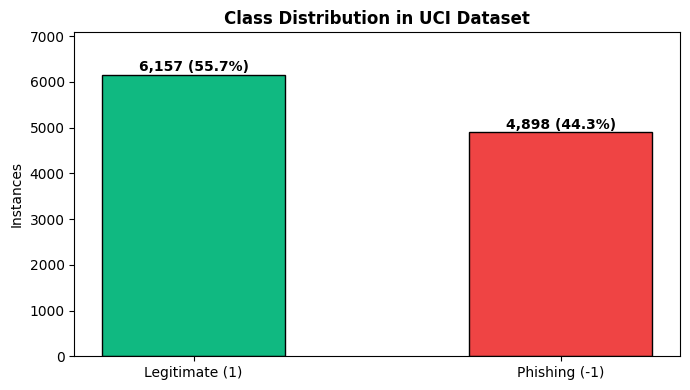

In [3]:
plt.figure(figsize=(7, 4))
counts = df["Result"].value_counts()
plt.bar(["Legitimate (1)", "Phishing (-1)"], [counts[1], counts[-1]], color=["#10b981", "#ef4444"], edgecolor="black", width=0.5)
plt.title("Class Distribution in UCI Dataset", fontsize=12, fontweight="bold")
plt.ylabel("Instances")
for i, v in enumerate([counts[1], counts[-1]]):
    pct = (v / len(df)) * 100
    plt.text(i, v + 80, f"{v:,} ({pct:.1f}%)", ha="center", fontweight="bold")
plt.ylim(0, max(counts)*1.15)
plt.tight_layout()
plt.show()

## 2. Exploratory Data Analysis: Correlation Heatmap
We evaluate the Pearson correlation among all 30 features and the target label (`Result`).

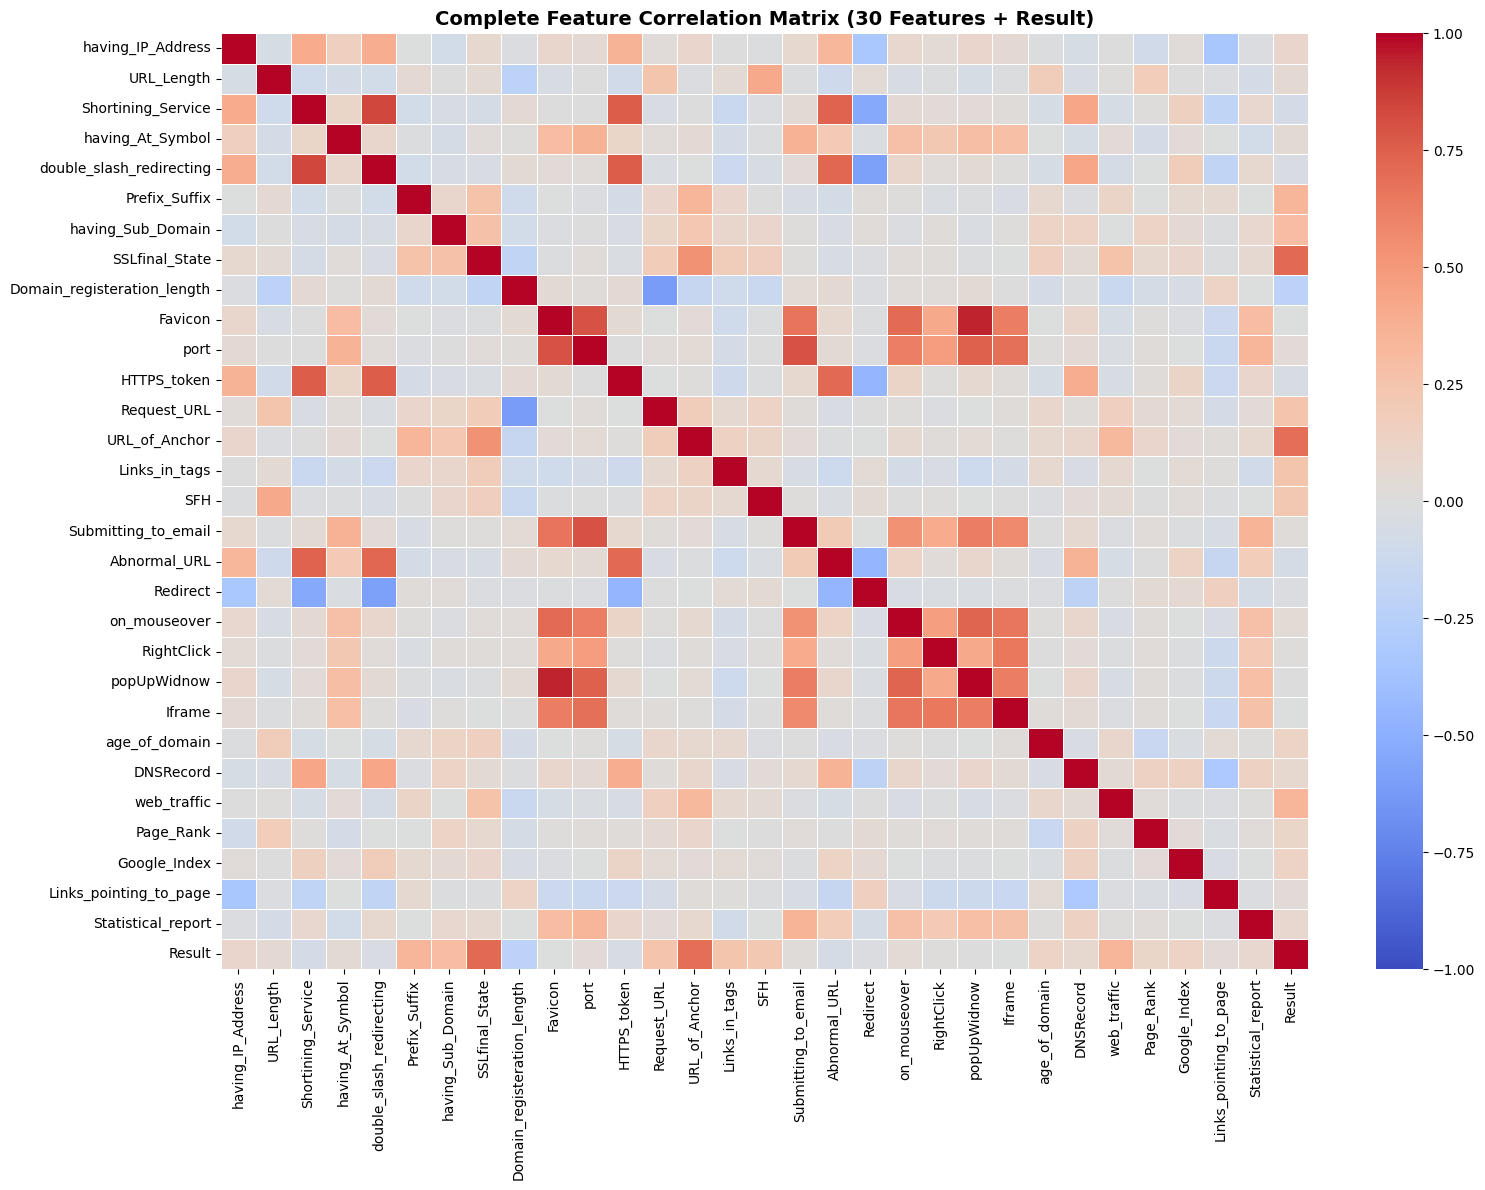

In [4]:
plt.figure(figsize=(16, 12))
sns.heatmap(df.corr(), cmap="coolwarm", vmin=-1, vmax=1, annot=False, linewidths=0.5)
plt.title("Complete Feature Correlation Matrix (30 Features + Result)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 3. Two-Model Strategy: Evaluation and Comparison
We evaluate the 5 classification algorithms across both experimental tracks:
- **Model A**: Decision Tree, Gaussian NB, Categorical NB, Random Forest, Logistic Regression on 30 features.
- **Model B**: Decision Tree, Gaussian NB, Categorical NB, Random Forest, Logistic Regression on 8 URL-only features.

In [5]:
comparison_csv = os.path.join(BASE_DIR, "results", "model_comparison.csv")
if os.path.exists(comparison_csv):
    res_df = pd.read_csv(comparison_csv)
    display(res_df)
else:
    print("Run evaluate_models.py to generate comparison table.")

,Track,Algorithm,Accuracy,Precision,Recall (Phishing),F1-Score,ROC-AUC,False Negatives (FN),False Positives (FP),Training Time (s),Pred Latency (ms/sample)
0,Model A (30 Features),Decision Tree,0.9701,0.9731,0.9592,0.9661,0.9778,40,26,6.912,0.0012
1,Model A (30 Features),Gaussian NB,0.6160,0.5359,0.9990,0.6975,0.9677,1,848,0.010,0.0016
2,Model A (30 Features),Categorical NB,0.9331,0.9379,0.9092,0.9233,0.9814,89,59,0.019,0.0008
3,Model A (30 Features),Random Forest,0.9760,0.9803,0.9653,0.9728,0.9963,34,19,20.023,0.0284
4,Model A (30 Features),Logistic Regression,0.9276,0.9343,0.9000,0.9168,0.9784,98,62,0.056,0.0006
5,Model B (8 URL Features),Decision Tree,0.7313,0.6729,0.7663,0.7166,0.8120,229,365,1.847,0.0015
6,Model B (8 URL Features),Gaussian NB,0.5857,0.5169,1.0000,0.6815,0.7616,0,916,0.002,0.0012
7,Model B (8 URL Features),Categorical NB,0.7291,0.6619,0.7949,0.7223,0.7972,201,398,0.003,0.0003
8,Model B (8 URL Features),Random Forest,0.7313,0.6751,0.7592,0.7147,0.8260,236,358,12.548,0.0113
9,Model B (8 URL Features),Logistic Regression,0.7101,0.6821,0.6480,0.6646,0.7830,345,296,0.020,0.0007


## 4. Live URL Feature Extraction & Prediction
We test our live inference engine on legitimate and suspicious test URLs.

In [6]:
sample_urls = [
    "https://www.google.com",
    "http://secure-paypal-login.update-billing.account-security.com//verify"
]

for url in sample_urls:
    pred = predict_url(url)
    print("=" * 60)
    print("URL:", pred["url"])
    print("Prediction:", pred["prediction"], f"({pred['risk_score']}% Risk Score)")
    print("Feature Vector:", pred["feature_vector"])
    print("Flagged Phishing Features:", pred["flagged_phishing_features"])

URL: https://www.google.com
Prediction: Legitimate (0.0% Risk Score)
Feature Vector: [1, 1, 1, 1, 1, 1, 1, 1]
Flagged Phishing Features: []
URL: http://secure-paypal-login.update-billing.account-security.com//verify
Prediction: Phishing (97.3% Risk Score)
Feature Vector: [1, 0, 1, 1, -1, -1, -1, 1]
Flagged Phishing Features: ['double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain']


## 5. Conclusion & Extension Integration
- **Model A** achieved ~97.6% accuracy by utilizing deep DOM and traffic features.
- **Model B** achieved ~73.1% accuracy and 76.6% phishing recall using only 8 address-bar URL features.
- The Decision Tree classifier was serialized into `model.json` and deployed inside the Google Chrome Extension (`extension/`) for instant client-side evaluation with 0ms server latency.